<a href="https://colab.research.google.com/github/Narmadha-H/MLA0202-FML/blob/main/ML12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Setup complete


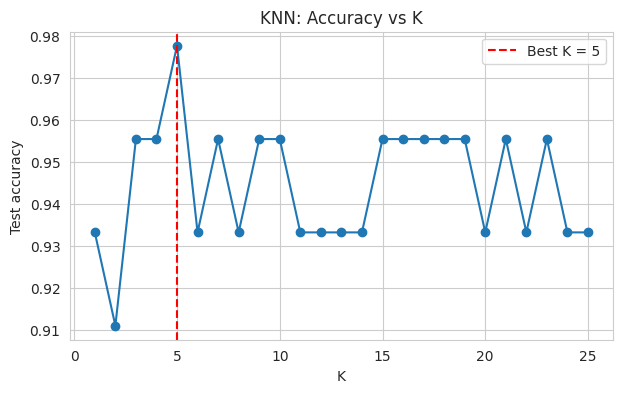

Accuracy: 0.978
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



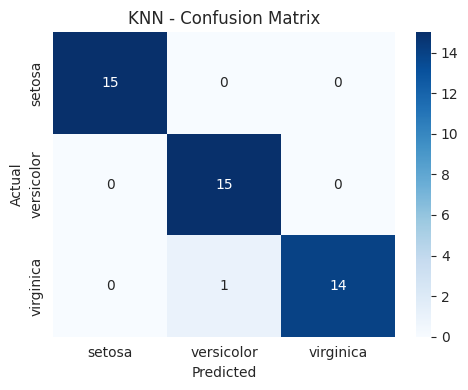

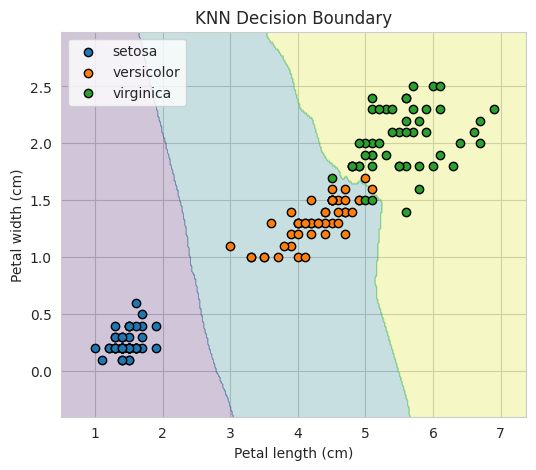

Prediction for [[5.1, 3.5, 1.4, 0.2]] -> setosa


In [1]:
# ---------- Common imports and helper functions ----------
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

from sklearn.datasets import load_iris, load_breast_cancer, fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression, Perceptron as SkPerceptron
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report, roc_curve, auc,
                             r2_score, mean_squared_error, mean_absolute_error,
                             precision_score, recall_score, f1_score)

sns.set_style("whitegrid")
rng = np.random.default_rng(42)

def plot_cm(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    plt.tight_layout(); plt.show()

def plot_reg(y_true, y_pred, title):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].scatter(y_true, y_pred, alpha=0.5, color="steelblue")
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax[0].plot(lims, lims, "r--", label="Perfect prediction")
    ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title(title); ax[0].legend()
    ax[1].hist(y_true - y_pred, bins=30, color="orange", edgecolor="black")
    ax[1].set_title("Residuals (Actual - Predicted)"); ax[1].set_xlabel("Error")
    plt.tight_layout(); plt.show()
    print(f"R2 = {r2_score(y_true, y_pred):.3f} | RMSE = {np.sqrt(mean_squared_error(y_true, y_pred)):.3f} | MAE = {mean_absolute_error(y_true, y_pred):.3f}")

def plot_importance(names, values, title):
    s = pd.Series(values, index=names).sort_values()
    s.plot(kind="barh", figsize=(7, 4), color="teal"); plt.title(title); plt.xlabel("Importance")
    plt.tight_layout(); plt.show()

def plot_boundary(model, X2, y, xlabel, ylabel, class_names, title):
    # model must already be trained on the 2 features in X2
    x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
    y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")
    for i, c in enumerate(class_names):
        plt.scatter(X2[y == i, 0], X2[y == i, 1], label=c, edgecolor="k")
    plt.xlabel(xlabel); plt.ylabel(ylabel); plt.title(title); plt.legend(); plt.show()
print("Setup complete")

iris = load_iris(); X, y = iris.data, iris.target; names = iris.target_names
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Accuracy for different K
ks = range(1, 26)
accs = [KNeighborsClassifier(k).fit(X_tr, y_tr).score(X_te, y_te) for k in ks]
best_k = ks[int(np.argmax(accs))]
plt.figure(figsize=(7, 4)); plt.plot(ks, accs, marker="o"); plt.axvline(best_k, color="r", ls="--", label=f"Best K = {best_k}")
plt.xlabel("K"); plt.ylabel("Test accuracy"); plt.title("KNN: Accuracy vs K"); plt.legend(); plt.show()

knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_tr, y_tr)
pred = knn.predict(X_te)
print("Accuracy:", round(accuracy_score(y_te, pred), 3)); print(classification_report(y_te, pred, target_names=names))
plot_cm(y_te, pred, names, "KNN - Confusion Matrix")

# Decision boundary using petal length and petal width
knn2 = KNeighborsClassifier(n_neighbors=best_k).fit(X[:, 2:4], y)
plot_boundary(knn2, X[:, 2:4], y, "Petal length (cm)", "Petal width (cm)", names, "KNN Decision Boundary")

# Predict a new flower
sample = [[5.1, 3.5, 1.4, 0.2]]
print("Prediction for", sample, "->", names[knn.predict(sample)[0]])